# Negative Binomial Model for Cyclist Volume in Adelaide

See `adelaide-models/model-2-data-notes.md` for discussion on decisions regarding variables and methods used.

## Variables:
- POW_CTW: N people who work in this DZN and cycle to work
- POW_FE: N people who work in this DZN and are fully engaged in employment or study
- PD_MB: MB population density
- DNL_DZN: Distance to nearest large DZN
- M_30_40, F_15_25: Age demographics, try males 30-40 and females 15-25 (best from Dadshova's)
- H_3500: Households with a THI of > 3500, place of enumeration, MB
- INF_CR: Listed cycle routes

__Monash Bicycle Infrastructure Classification__ - Binary dummy variables for every type of bicycle infrastructure

- MBI_BP: Dedicated bike path, Shared bike path
- MBI_PP: Pedestrian path/street with cycling allowed
- MBI_PL: Protected bike lane
- MBI_BL: Buffered bike lane (kerb-side), Buffered bike lane (road-side), Buffered bike lane (both sides)
- MBI_PTL: Painted bike lane, Painted bike lane (single-side)
- MBI_Ad: Advisory bike lane, Advisory bike lane (single-side), Peak hour advisory bike lane, Peak hour advisory bike lane (single-side)
- MBI_PkPt: Peak hour painted bike lane, Peak hour painted bike lane (single-side)
- MBI_Sh: Sharrow
- MBI_SZ: Shared zone
- MBI_Bus: Bus lane with cycling allowed
- MBI_Mx: Mixed traffic
- MBI_No: Bicyclists dismount, Pedestrian path/street with cycling not allowed

## Correlations

There is bound to be a lot of correlation between many of the variables chosen for this model - eg. the Monash Classifiers. The goal of this model is to identify the best variables to use for the final model.

# Retrieve the graph

__Before__ running this notebook, ensure `graph_generation/GRAPH_SETUP.ipynb` and then `graph_generation/GRAPH_LOAD.ipynb` have both been run. Ensure `graph_generation/graph_cache/graph_loaded.graphml` exists.

The graph is roughly 1GB, so this block can take a long time.

In [ ]:
import osmnx as ox
import pandas as pd
import numpy as np
import geopandas as gpd
import networkx as nx
from scipy.spatial import cKDTree

graphml_path = "./graph_generation/graph_cache/graph_loaded.graphml"
G = ox.load_graphml(filepath=graphml_path)
print(f"Loaded graph: {len(G.nodes)} nodes, {len(G.edges)} edges")

Loaded graph: 466150 nodes, 893094 edges


# Constructing the regression matrix

In [4]:
import pandas as pd

counts_path = "./all-data/super-tuesday-normalised/counts-2026.csv"

required_cols = ["total-count", "x", "y"]

REGRESSION_TABLE = pd.read_csv(counts_path)

missing = [col for col in required_cols if col not in REGRESSION_TABLE.columns]
if missing:
    raise ValueError(f"Missing required count columns: {missing}")

REGRESSION_TABLE = REGRESSION_TABLE[required_cols].copy()
REGRESSION_TABLE = REGRESSION_TABLE.rename(columns={"total-count": "COUNT"})
REGRESSION_TABLE["COUNT"] = pd.to_numeric(REGRESSION_TABLE["COUNT"], errors="coerce")
REGRESSION_TABLE["x"] = pd.to_numeric(REGRESSION_TABLE["x"], errors="coerce")
REGRESSION_TABLE["y"] = pd.to_numeric(REGRESSION_TABLE["y"], errors="coerce")

REGRESSION_TABLE = REGRESSION_TABLE.dropna(subset=["COUNT", "x", "y"]).reset_index(drop=True)

print(REGRESSION_TABLE.head())
print(f"Rows loaded: {len(REGRESSION_TABLE)}")

   COUNT           x          y
0   49.0  138.588749 -34.899506
1   53.0  138.589951 -34.902941
2   93.0  138.599362 -34.902090
3   82.0  138.595016 -34.903023
4   44.0  138.611103 -34.903433
Rows loaded: 130


__*Join all graph attributes from nearest edge*__

In [5]:
# 1. Build edge GeoDataFrame from graph (physical edges only, deduplicated)
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G, nodes=True, edges=True)
edges_gdf = edges_gdf.reset_index()  # columns: u, v, key, ...

# Create undirected edge identifier for deduplication
edges_gdf["_u_v"] = [tuple(sorted((u, v))) for u, v in zip(edges_gdf["u"], edges_gdf["v"])]
edges_phys = edges_gdf.drop_duplicates(subset=["_u_v", "key"]).copy()
edges_phys = edges_phys.reset_index(drop=True)

# 2. Project edges to metric CRS for distance calculations
metric_crs = edges_phys.estimate_utm_crs()
edges_metric = edges_phys.to_crs(metric_crs)

# 3. Build cKDTree on edge midpoints for fast nearest-neighbor search
edge_midpoints = edges_metric.geometry.interpolate(0.5, normalized=True)
midpoint_coords = np.column_stack([edge_midpoints.x.values, edge_midpoints.y.values])
edge_tree = cKDTree(midpoint_coords)

# 4. Convert count points to GeoDataFrame and project
count_points = gpd.GeoDataFrame(
    REGRESSION_TABLE.copy(),
    geometry=gpd.points_from_xy(REGRESSION_TABLE["x"], REGRESSION_TABLE["y"]),
    crs="EPSG:4326",
)
count_points_metric = count_points.to_crs(metric_crs)
count_coords = np.column_stack([count_points_metric.geometry.x.values, count_points_metric.geometry.y.values])

# 4. Query nearest edge for each count point
distances, indices = edge_tree.query(count_coords, k=1)
REGRESSION_TABLE["dist_to_edge"] = distances / 1000  # km
REGRESSION_TABLE["nearest_edge_idx"] = indices

# 5. Join edge attributes to count points
edge_attr_cols = [
    'INF_CR',
    'MBI_BP',
    'MBI_PP',
    'MBI_PL',
    'MBI_BL',
    'MBI_PTL',
    'MBI_Ad',
    'MBI_PkPt',
    'MBI_Sh',
    'MBI_SZ',
    'MBI_Bus',
    'MBI_Mx',
    'MBI_No',
    'DNL_DZN',
    'PD_MB',
    'POW_CTW',
    'POW_FE',
    'M_30_40',
    'F_15_25',
    'H_3500',
]
for col in edge_attr_cols:
    if col in edges_phys.columns:
        REGRESSION_TABLE[col] = edges_phys.iloc[indices][col].values
    else:
        print(f"Warning: {col} not found in edges")
        REGRESSION_TABLE[col] = 0

print(f"Joined attributes. Shape: {REGRESSION_TABLE.shape}")
print(REGRESSION_TABLE.head())

Joined attributes. Shape: (130, 25)
   COUNT           x          y  dist_to_edge  nearest_edge_idx INF_CR MBI_BP  \
0   49.0  138.588749 -34.899506      0.001118            425592      0      1   
1   53.0  138.589951 -34.902941      0.002922            227372      0      0   
2   93.0  138.599362 -34.902090      0.004407            205671      0      1   
3   82.0  138.595016 -34.903023      0.003487            262606      0      1   
4   44.0  138.611103 -34.903433      0.020760            428209      0      0   

  MBI_PP MBI_PL MBI_BL  ... MBI_Bus MBI_Mx MBI_No             DNL_DZN  \
0      0      0      0  ...       0      0      0  1956.9810627377258   
1      0      0      0  ...       0      1      0  1602.8676807209872   
2      0      0      0  ...       0      0      0  1590.2776104412778   
3      0      0      0  ...       0      0      0  1527.4214372068666   
4      0      0      0  ...       0      0      0   1835.182619287391   

                PD_MB POW_CTW POW_FE M

# Exploratory Data Analysis

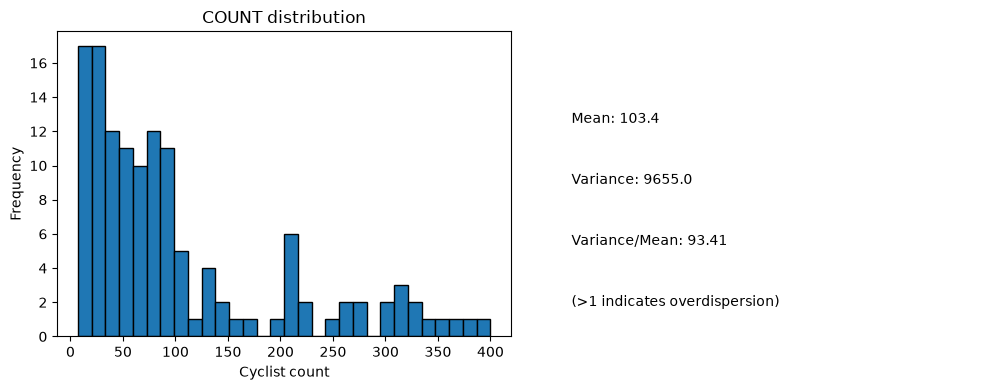

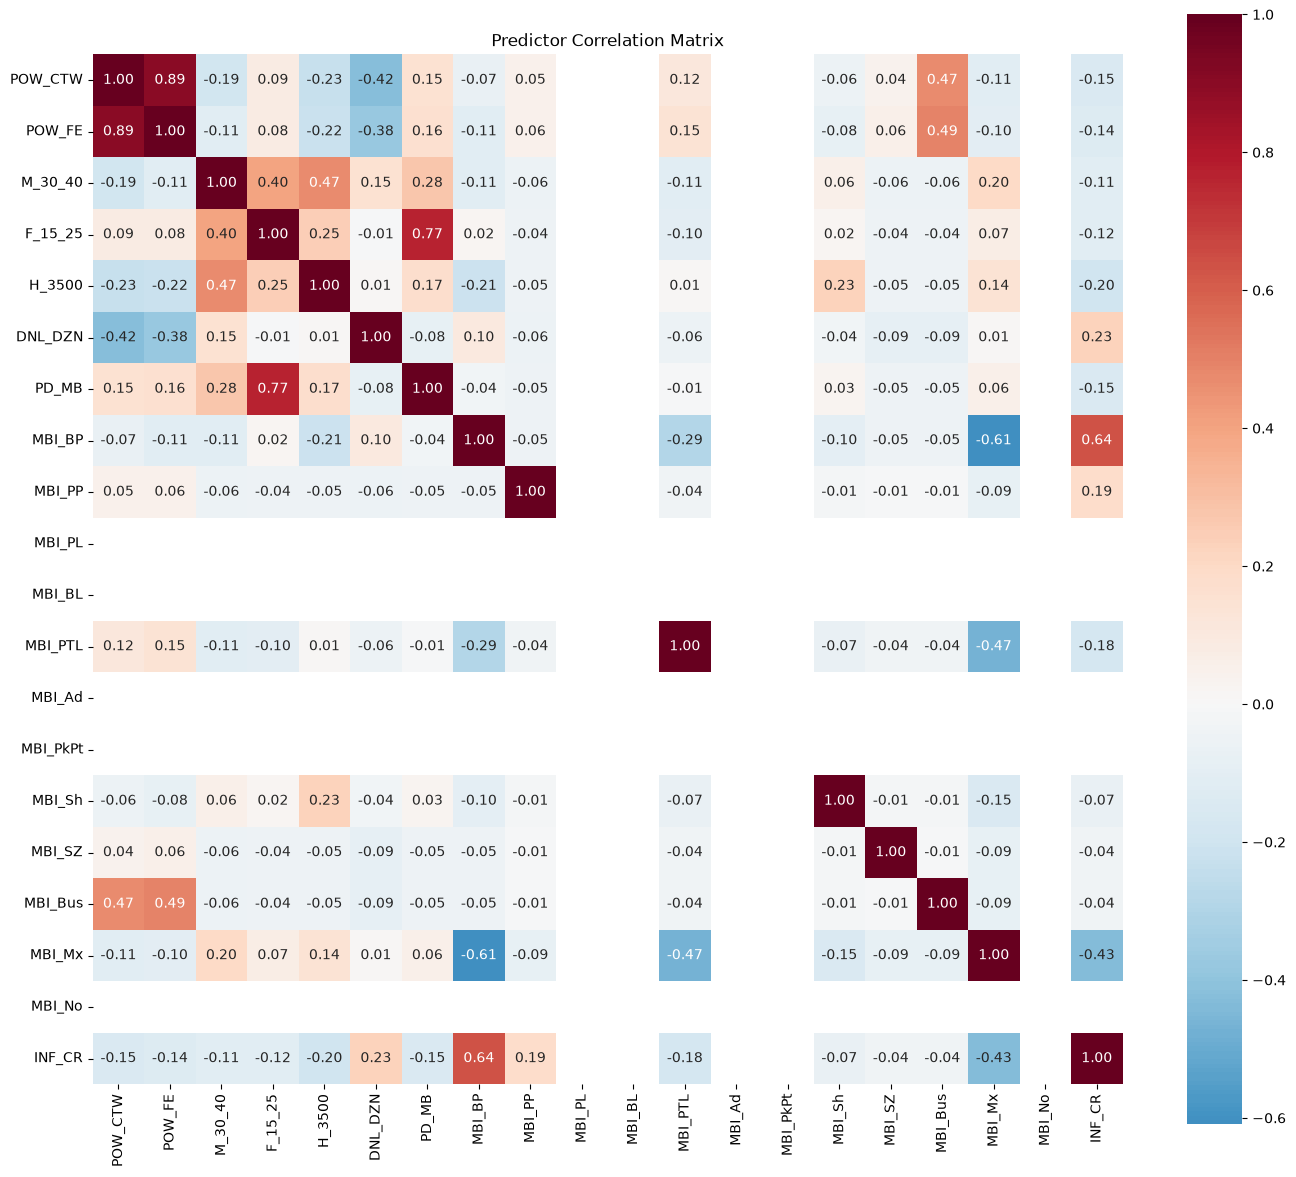

    variable           VIF
8     MBI_BP  1.000800e+15
9     MBI_PP  1.000800e+15
12   MBI_PTL  1.000800e+15
15    MBI_Sh  1.000800e+15
16    MBI_SZ  1.000800e+15
17   MBI_Bus  1.000800e+15
18    MBI_Mx  1.000800e+15
1    POW_CTW  5.611056e+00
2     POW_FE  5.574476e+00
4    F_15_25  2.779622e+00
7      PD_MB  2.560638e+00
20    INF_CR  2.019121e+00
3    M_30_40  1.583703e+00
5     H_3500  1.536598e+00
6    DNL_DZN  1.350737e+00
0      const  1.000000e+00
10    MBI_PL           NaN
11    MBI_BL           NaN
13    MBI_Ad           NaN
14  MBI_PkPt           NaN
19    MBI_No           NaN


/var/folders/2d/s2g_n94s3yg4d7k19tqxsq8w0000gn/T/ipykernel_39010/951413526.py:46: UserWarning: The design matrix is poorly conditioned (condition number=2.40e+34). VIF calculations may be numerically unstable.
  vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
/opt/anaconda3/envs/CyclistVolumeModelling/lib/python3.12/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/var/folders/2d/s2g_n94s3yg4d7k19tqxsq8w0000gn/T/ipykernel_39010/951413526.py:46: UserWarning: The design matrix is poorly conditioned (condition number=2.40e+34). VIF calculations may be numerically unstable.
  vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
/opt/anaconda3/envs/CyclistVolumeModelling/lib/python3.12/site-packages/statsmodels/stats/outliers_influence.py:235: Sin

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Target distribution
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(REGRESSION_TABLE['COUNT'], bins=30, edgecolor='black')
axes[0].set_title('COUNT distribution')
axes[0].set_xlabel('Cyclist count')
axes[0].set_ylabel('Frequency')

mean_count = REGRESSION_TABLE['COUNT'].mean()
var_count = REGRESSION_TABLE['COUNT'].var()
axes[1].text(0.1, 0.7, f'Mean: {mean_count:.1f}')
axes[1].text(0.1, 0.5, f'Variance: {var_count:.1f}')
axes[1].text(0.1, 0.3, f'Variance/Mean: {var_count/mean_count:.2f}')
axes[1].text(0.1, 0.1, '(>1 indicates overdispersion)')
axes[1].set_axis_off()
plt.tight_layout()
plt.show()

# 2. Correlation matrix of numeric predictors
predictor_cols = [
    'POW_CTW', 'POW_FE', 'M_30_40', 'F_15_25', 'H_3500',
    'DNL_DZN', 'PD_MB',
    'MBI_BP', 'MBI_PP', 'MBI_PL', 'MBI_BL', 'MBI_PTL',
    'MBI_Ad', 'MBI_PkPt', 'MBI_Sh', 'MBI_SZ', 'MBI_Bus',
    'MBI_Mx', 'MBI_No', 'INF_CR'
]
numeric_cols = [c for c in predictor_cols if c in REGRESSION_TABLE.columns]
corr = REGRESSION_TABLE[numeric_cols].corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True)
plt.title('Predictor Correlation Matrix')
plt.tight_layout()
plt.show()

# 3. VIF for multicollinearity check
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif = REGRESSION_TABLE[numeric_cols].fillna(0)
X_vif = add_constant(X_vif)
vif_data = pd.DataFrame()
vif_data['variable'] = X_vif.columns
vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
print(vif_data.sort_values('VIF', ascending=False))

# Prepare Design Matrix & Target

In [11]:
import statsmodels.api as sm
import numpy as np

# Define final predictor set (drop MBI_Mx as reference)
mbi_cols = ['MBI_BP', 'MBI_PP', 'MBI_PL', 'MBI_BL', 'MBI_PTL',
            'MBI_Ad', 'MBI_PkPt', 'MBI_Sh', 'MBI_SZ', 'MBI_Bus',
            'MBI_No']  # MBI_Mx is reference

predictor_cols = [
    'POW_CTW', 'POW_FE', 'M_30_40', 'F_15_25', 'H_3500',
    'DNL_DZN', 'PD_MB', 'D_CBD',
    'IS_CYCLE_ROUTE',
] + mbi_cols

# Keep only available columns
predictor_cols = [c for c in predictor_cols if c in REGRESSION_TABLE.columns]

# Drop rows with any NaN
model_data = REGRESSION_TABLE[['COUNT'] + predictor_cols].dropna()

# REMOVE zero-variance / constant columns
X_check = model_data[predictor_cols]
zero_var_cols = [c for c in X_check.columns if X_check[c].nunique() <= 1]
if zero_var_cols:
    print(f"Dropping zero-variance columns: {zero_var_cols}")
    predictor_cols = [c for c in predictor_cols if c not in zero_var_cols]
    model_data = model_data[['COUNT'] + predictor_cols]

# Also drop perfectly correlated columns (pairwise r=1)
corr_matrix = model_data[predictor_cols].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
perfect_corr = [col for col in upper.columns if any(upper[col] == 1.0)]
if perfect_corr:
    print(f"Dropping perfectly correlated columns: {perfect_corr}")
    predictor_cols = [c for c in predictor_cols if c not in perfect_corr]
    model_data = model_data[['COUNT'] + predictor_cols]

y = model_data['COUNT']
X = sm.add_constant(model_data[predictor_cols])

print(f"Final X shape: {X.shape}")
print(f"Predictors: {predictor_cols}")
print(f"y mean: {y.mean():.2f}, var: {y.var():.2f}")

Dropping zero-variance columns: ['MBI_PL', 'MBI_BL', 'MBI_Ad', 'MBI_PkPt', 'MBI_No']
Final X shape: (130, 14)
Predictors: ['POW_CTW', 'POW_FE', 'M_30_40', 'F_15_25', 'H_3500', 'DNL_DZN', 'PD_MB', 'MBI_BP', 'MBI_PP', 'MBI_PTL', 'MBI_Sh', 'MBI_SZ', 'MBI_Bus']
y mean: 103.36, var: 9654.98


In [12]:
# Export design matrix and target for inspection
export_df = X.copy()
export_df['COUNT'] = y.values
export_df.to_csv('./model_2_X_y.csv', index=False)
print(f"Exported X and y to ./model_2_X_y.csv (shape: {export_df.shape})")
print(f"Columns: {list(export_df.columns)}")

Exported X and y to ./model_2_X_y.csv (shape: (130, 15))
Columns: ['const', 'POW_CTW', 'POW_FE', 'M_30_40', 'F_15_25', 'H_3500', 'DNL_DZN', 'PD_MB', 'MBI_BP', 'MBI_PP', 'MBI_PTL', 'MBI_Sh', 'MBI_SZ', 'MBI_Bus', 'COUNT']


# Fit Negative Binomial Model (NB2)

In [13]:
# NB model with ridge regularization to handle near-singular
nb_model = sm.NegativeBinomial(y, X).fit_regularized(method='l1', alpha=0.01, maxiter=200, disp=True)
# Or if that fails, use statsmodels' built-in handling:
# nb_model = sm.NegativeBinomial(y, X).fit(method='nm', maxiter=200, disp=True)  # Nelder-Mead

print(nb_model.summary())
nb_model.save('./model_2_nb.pkl')

Optimization terminated successfully    (Exit mode 0)
            Current function value: 5.146191829460107
            Iterations: 133
            Function evaluations: 167
            Gradient evaluations: 133
                     NegativeBinomial Regression Results                      
Dep. Variable:                  COUNT   No. Observations:                  130
Model:               NegativeBinomial   Df Residuals:                      116
Method:                           MLE   Df Model:                           13
Date:                Sun, 01 Nov 2026   Pseudo R-squ.:                 0.08566
Time:                        16:53:09   Log-Likelihood:                -668.93
converged:                       True   LL-Null:                       -731.60
Covariance Type:            nonrobust   LLR p-value:                 1.760e-20
                 coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------

/opt/anaconda3/envs/CyclistVolumeModelling/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:3997: RuntimeWarning: overflow encountered in exp
  return np.exp(linpred)
/opt/anaconda3/envs/CyclistVolumeModelling/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:3709: RuntimeWarning: divide by zero encountered in log
  llf = coeff + size * np.log(prob) + endog * np.log(1 - prob)
/opt/anaconda3/envs/CyclistVolumeModelling/lib/python3.12/site-packages/statsmodels/base/l1_slsqp.py:129: ConvergenceWarning: QC check did not pass for 4 out of 15 parameters
Try increasing solver accuracy or number of iterations, decreasing alpha, or switch solvers
  passed = l1_solvers_common.qc_results(
/opt/anaconda3/envs/CyclistVolumeModelling/lib/python3.12/site-packages/statsmodels/base/l1_slsqp.py:135: ConvergenceWarning: Could not trim params automatically due to failed QC check. Trimming using trim_mode == 'size' will still work.
  params, trimmed = l1_solvers_common.

# Model Diagnostics

Dispersion parameter (alpha): 0.3328
  (alpha > 0 confirms overdispersion; NB preferred over Poisson)
Pearson chi2/df: 1.2753 (should be ~1)


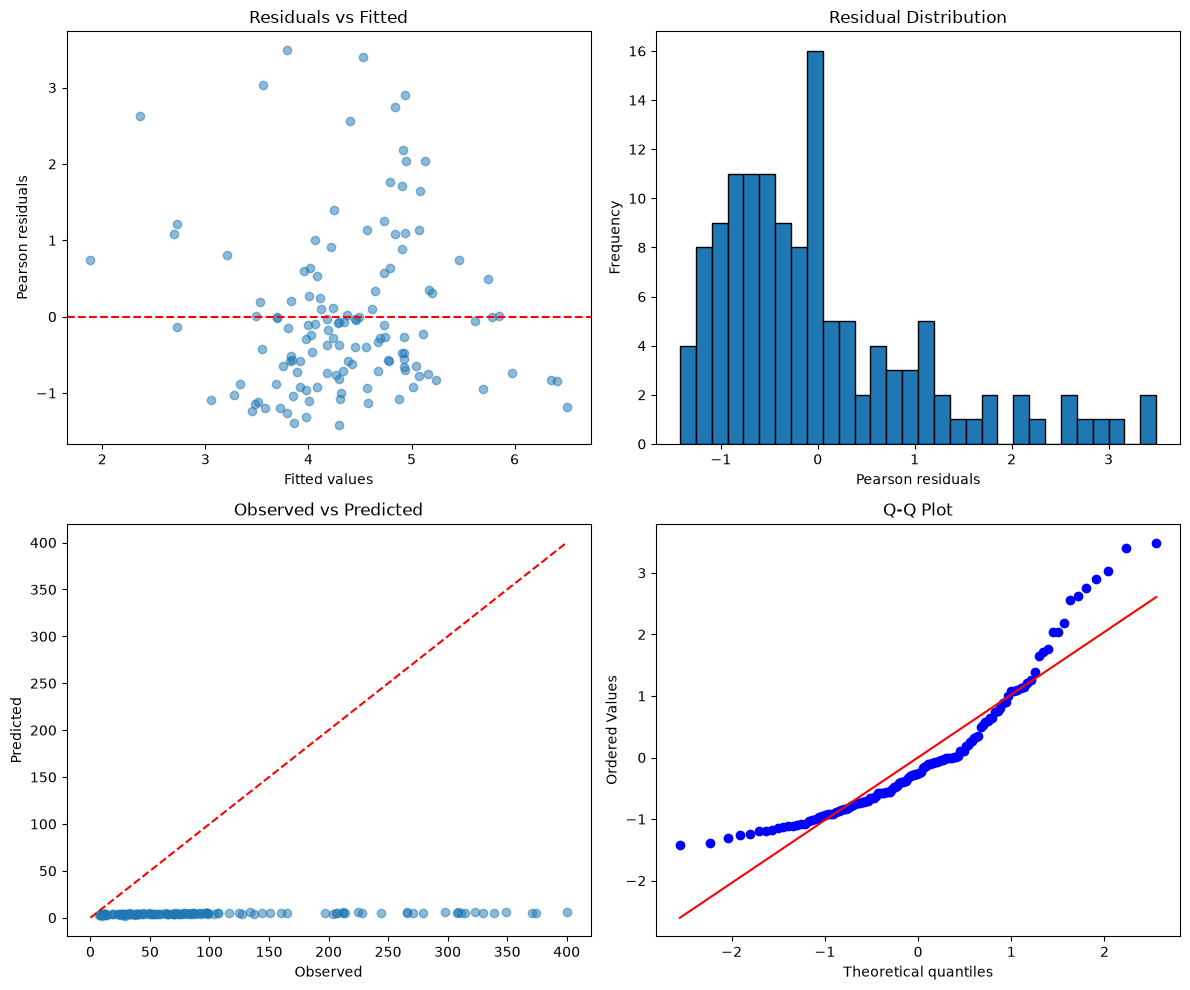


AIC: NB=1367.9, Poisson=43866808.4
BIC: NB=1410.9, Poisson=43866848.6
(Lower is better; NB should win if overdispersed)


/opt/anaconda3/envs/CyclistVolumeModelling/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:1619: RuntimeWarning: overflow encountered in exp
  L = np.exp(np.dot(X, params) + offset + exposure)
/opt/anaconda3/envs/CyclistVolumeModelling/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:268: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mlefit = super().fit(
/opt/anaconda3/envs/CyclistVolumeModelling/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [14]:
# 1. Dispersion parameter
alpha = nb_model.params.get('alpha', np.nan)
print(f"Dispersion parameter (alpha): {alpha:.4f}")
print(f"  (alpha > 0 confirms overdispersion; NB preferred over Poisson)")

# 2. Pearson chi2 / df
pearson_resid = nb_model.resid_pearson
pearson_chi2 = np.sum(pearson_resid**2)
df_resid = nb_model.df_resid
dispersion = pearson_chi2 / df_resid
print(f"Pearson chi2/df: {dispersion:.4f} (should be ~1)")

# 3. Residual plots
fitted = nb_model.fittedvalues
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].scatter(fitted, pearson_resid, alpha=0.5)
axes[0, 0].axhline(0, color='red', linestyle='--')
axes[0, 0].set_xlabel('Fitted values')
axes[0, 0].set_ylabel('Pearson residuals')
axes[0, 0].set_title('Residuals vs Fitted')

axes[0, 1].hist(pearson_resid, bins=30, edgecolor='black')
axes[0, 1].set_xlabel('Pearson residuals')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Residual Distribution')

axes[1, 0].scatter(model_data['COUNT'], fitted, alpha=0.5)
axes[1, 0].plot([0, model_data['COUNT'].max()], [0, model_data['COUNT'].max()], 'r--')
axes[1, 0].set_xlabel('Observed')
axes[1, 0].set_ylabel('Predicted')
axes[1, 0].set_title('Observed vs Predicted')

# Q-Q plot
from scipy import stats
stats.probplot(pearson_resid, dist='norm', plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()

# 4. Compare with Poisson (AIC/BIC)
poisson_model = sm.Poisson(y, X).fit(method='bfgs', maxiter=200, disp=False)
print(f"\nAIC: NB={nb_model.aic:.1f}, Poisson={poisson_model.aic:.1f}")
print(f"BIC: NB={nb_model.bic:.1f}, Poisson={poisson_model.bic:.1f}")
print(f"(Lower is better; NB should win if overdispersed)")